# Course 12: AI for Accessibility
## Session 1: Disability, accessibility and AI

**Goal:** compute WCAG contrast ratios from sRGB colours, find the nearest shade that passes, simulate colour vision deficiency with the Machado et al. (2009) matrices, and choose a chart palette that stays distinguishable.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: relative luminance and the contrast ratio
The Web Content Accessibility Guidelines (WCAG 2.2, W3C 2023) measure how well text stands out from its background with a **contrast ratio** built from each colour's **relative luminance** $L$: its brightness on a scale from 0 (black) to 1 (white), weighted the way the eye weights red, green and blue light.

1. Divide each 8-bit sRGB channel (0–255) by 255.
2. Undo the gamma encoding (screens store colours non-linearly): $c_{\text{lin}} = c / 12.92$ if $c \le 0.04045$, otherwise $\left(\frac{c + 0.055}{1.055}\right)^{2.4}$.
3. $L = 0.2126\,R_{\text{lin}} + 0.7152\,G_{\text{lin}} + 0.0722\,B_{\text{lin}}$.
4. Contrast ratio $= \dfrac{L_1 + 0.05}{L_2 + 0.05}$, where $L_1$ is the lighter colour. It runs from 1:1 (same colour) to 21:1 (black on white).

Level AA asks for at least **4.5:1** for normal text, and **3:1** for large text (at least 18 point, or 14 point bold) and for user-interface parts and meaningful graphics such as chart lines (success criterion 1.4.11). Level AAA asks for 7:1 for normal text.

**On paper first:** (a) the contrast of black on white; (b) grey `#777777` has all three channels equal to 119/255 = 0.4667. Compute its linear value, its luminance and its contrast against white. Does it pass AA for normal text? The cell checks your answers.

In [1]:
import time
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from sklearn.datasets import load_sample_image

t_start = time.time()
np.random.seed(0)

def hex_to_rgb(h):
    h = h.lstrip("#")
    return np.array([int(h[i:i + 2], 16) for i in (0, 2, 4)]) / 255.0

def to_hex(c):
    return "#" + "".join(f"{int(round(v * 255)):02x}" for v in np.clip(c, 0, 1))

def srgb_to_linear(c):
    c = np.asarray(c, dtype=float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(c):
    c = np.clip(np.asarray(c, dtype=float), 0, 1)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1 / 2.4) - 0.055)

def luminance(rgb):
    lin = srgb_to_linear(rgb)
    return lin[..., 0] * 0.2126 + lin[..., 1] * 0.7152 + lin[..., 2] * 0.0722

def contrast(c1, c2):
    l1, l2 = luminance(c1), luminance(c2)
    return (np.maximum(l1, l2) + 0.05) / (np.minimum(l1, l2) + 0.05)

WHITE, BLACK = np.ones(3), np.zeros(3)
c = 119 / 255
print(f"(a) black on white: contrast {contrast(BLACK, WHITE):.2f}:1")
print(f"(b) #777777: channel {c:.4f}, linear value {srgb_to_linear(c):.4f}, luminance {luminance(hex_to_rgb('#777777')):.4f}, "
      f"contrast on white {contrast(hex_to_rgb('#777777'), WHITE):.3f}:1")
print(f"    one step darker, #767676: contrast on white {contrast(hex_to_rgb('#767676'), WHITE):.3f}:1")

(a) black on white: contrast 21.00:1
(b) #777777: channel 0.4667, linear value 0.1845, luminance 0.1845, contrast on white 4.478:1
    one step darker, #767676: contrast on white 4.542:1


### 2. A contrast report for some real-looking colour pairs
A checker like this runs inside browser developer tools and accessibility audits. Each row is a foreground (text or graphic) colour on a background, with the three thresholds: 3:1 (large text and graphics), 4.5:1 (AA, normal text) and 7:1 (AAA, normal text). The orange, green and pink are matplotlib's default chart colours; `#0072B2` and `#E69F00` are from the Okabe–Ito palette, designed for colour-blind readers (Okabe & Ito 2008).

In [2]:
pairs = [("light grey placeholder text", "#999999", "#ffffff"),
         ("grey text #767676", "#767676", "#ffffff"),
         ("pure red error text", "#ff0000", "#ffffff"),
         ("white text on an orange button (matplotlib C1)", "#ffffff", "#ff7f0e"),
         ("matplotlib green line (C2) on white", "#2ca02c", "#ffffff"),
         ("matplotlib pink line (C6) on white", "#e377c2", "#ffffff"),
         ("Okabe-Ito orange line on white", "#E69F00", "#ffffff"),
         ("white text on Okabe-Ito blue", "#ffffff", "#0072B2"),
         ("yellow text on black", "#ffff00", "#000000"),
         ("dark grey text on near-black (dark mode)", "#555555", "#121212")]
print(f"{'pair':48s} {'ratio':>7s}   3:1   4.5:1  7:1")
for name, fg, bg in pairs:
    r = contrast(hex_to_rgb(fg), hex_to_rgb(bg))
    marks = "  ".join(" pass" if r >= t else " FAIL" for t in (3.0, 4.5, 7.0))
    print(f"{name:48s} {r:6.2f}:1  {marks}")

pair                                               ratio   3:1   4.5:1  7:1
light grey placeholder text                        2.85:1   FAIL   FAIL   FAIL
grey text #767676                                  4.54:1   pass   pass   FAIL
pure red error text                                4.00:1   pass   FAIL   FAIL
white text on an orange button (matplotlib C1)     2.53:1   FAIL   FAIL   FAIL
matplotlib green line (C2) on white                3.40:1   pass   FAIL   FAIL
matplotlib pink line (C6) on white                 2.73:1   FAIL   FAIL   FAIL
Okabe-Ito orange line on white                     2.25:1   FAIL   FAIL   FAIL
white text on Okabe-Ito blue                       5.19:1   pass   pass   FAIL
yellow text on black                              19.56:1   pass   pass   pass
dark grey text on near-black (dark mode)           2.51:1   FAIL   FAIL   FAIL


### 3. The nearest passing shade
When a brand colour fails, designers usually keep its hue and change only how dark it is. We darken a colour by scaling its sRGB channels towards black, $c' = (1 - t)\,c$, and find the smallest $t$ that reaches the target by bisection (contrast with white grows steadily as $t$ grows). For a dark background we lighten instead, $c' = c + t(1 - c)$.

In [3]:
def shade_to_pass(c, bg, target, lighten=False):
    # smallest change t in [0, 1] that reaches the target contrast, found by bisection
    move = (lambda t: c + t * (1 - c)) if lighten else (lambda t: (1 - t) * c)
    if contrast(c, bg) >= target:
        return c, 0.0
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if contrast(move(mid), bg) >= target else (mid, hi)
    return move(hi), hi

DARK = hex_to_rgb("#121212")
print("on white: the lightest version of each colour that passes")
for h in ["#ff7f0e", "#2ca02c", "#bcbd22", "#17becf", "#e377c2"]:
    c0 = hex_to_rgb(h)
    out = []
    for target in (3.0, 4.5):
        c1, t = shade_to_pass(c0, WHITE, target)
        out.append(f"{target}:1 -> {to_hex(c1)} (t = {t:.3f})")
    print(f"  {h} (now {contrast(c0, WHITE):.2f}:1): " + "; ".join(out))
print("on #121212: the darkest version of each colour that passes 4.5:1")
for h in ["#1f77b4", "#d62728", "#9467bd", "#8c564b"]:
    c0 = hex_to_rgb(h)
    c1, t = shade_to_pass(c0, DARK, 4.5, lighten=True)
    print(f"  {h} (now {contrast(c0, DARK):.2f}:1) -> {to_hex(c1)} (t = {t:.3f}, {contrast(c1, DARK):.2f}:1)")

on white: the lightest version of each colour that passes
  #ff7f0e (now 2.53:1): 3.0:1 -> #ea740d (t = 0.084); 4.5:1 -> #bb5d0a (t = 0.269)
  #2ca02c (now 3.40:1): 3.0:1 -> #2ca02c (t = 0.000); 4.5:1 -> #268926 (t = 0.146)
  #bcbd22 (now 2.01:1): 3.0:1 -> #999a1c (t = 0.185); 4.5:1 -> #7a7b16 (t = 0.350)
  #17becf (now 2.26:1): 3.0:1 -> #14a4b3 (t = 0.136); 4.5:1 -> #10838f (t = 0.310)
  #e377c2 (now 2.73:1): 3.0:1 -> #d871b9 (t = 0.048); 4.5:1 -> #ad5a93 (t = 0.240)
on #121212: the darkest version of each colour that passes 4.5:1
  #1f77b4 (now 3.89:1) -> #3182ba (t = 0.082, 4.50:1)
  #d62728 (now 3.73:1) -> #dc4748 (t = 0.149, 4.50:1)
  #9467bd (now 4.40:1) -> #9569be (t = 0.013, 4.50:1)
  #8c564b (now 3.16:1) -> #9f7168 (t = 0.162, 4.50:1)


### 4. Simulating colour vision deficiency
The retina has three kinds of cone cells, most sensitive to long (L, "red"), medium (M, "green") and short (S, "blue") wavelengths. In **protanopia**, **deuteranopia** and **tritanopia** one kind is missing, so the person is a dichromat; in the milder anomalous forms the cones are present but shifted. Red–green deficiency is the common kind: among people of Northern European ancestry it affects about 1 in 12 males and 1 in 200 females, while blue–yellow (tritan) deficiency affects fewer than 1 in 10,000 people worldwide (MedlinePlus Genetics). Rates differ between populations.

Machado, Oliveira & Fernandes (2009) model each type and severity with a single 3×3 matrix that acts on **linear** RGB. We use their severity-1.0 (dichromat) matrices on scikit-learn's flower photo. Treat the tritan result as rougher: the model handles tritan deficiency only approximately. To measure what is lost we convert to CIELAB, a colour space built so that distance roughly follows perceived difference: $L^*$ is lightness, $a^*$ runs from green to red and $b^*$ from blue to yellow.

check: white -> Lab [100.   0.   0.], black -> Lab [0. 0. 0.]
flower photo 640 x 427 pixels; spread (standard deviation) of each CIELAB channel:


  normal        L* 21.18  a* (green-red) 19.42  b* (blue-yellow) 20.73   mean change from the original  0.00 (Delta E)


  protanopia    L* 19.63  a* (green-red)  1.89  b* (blue-yellow) 18.24   mean change from the original 18.56 (Delta E)
  deuteranopia  L* 22.23  a* (green-red)  2.56  b* (blue-yellow) 21.73   mean change from the original 18.99 (Delta E)


  tritanopia    L* 20.96  a* (green-red) 26.26  b* (blue-yellow) 11.21   mean change from the original 11.47 (Delta E)


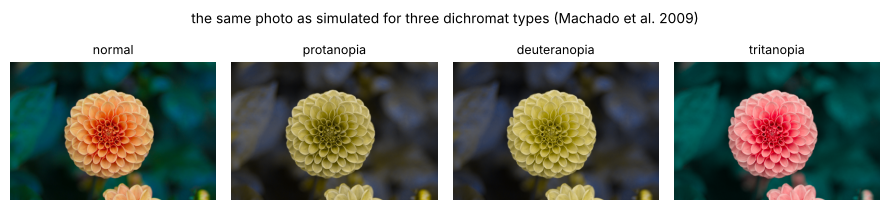

In [4]:
CVD = {  # Machado et al. (2009), severity 1.0, applied to linear RGB
    "protanopia": np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    "deuteranopia": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "tritanopia": np.array([[1.255528, -0.076749, -0.178779], [-0.078411, 0.930809, 0.147602], [0.004733, 0.691367, 0.303900]])}
KINDS = ["normal", "protanopia", "deuteranopia", "tritanopia"]

def simulate_linear(rgb, kind):
    lin = srgb_to_linear(rgb)
    return lin if kind == "normal" else np.clip(lin @ CVD[kind].T, 0, 1)

M_XYZ = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])   # linear sRGB -> CIE XYZ (D65)
WHITE_XYZ = M_XYZ @ np.ones(3)

def linear_to_lab(lin):
    t = (lin @ M_XYZ.T) / WHITE_XYZ
    d = 6 / 29
    f = np.where(t > d ** 3, np.cbrt(t), t / (3 * d * d) + 4 / 29)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

print(f"check: white -> Lab {linear_to_lab(np.ones(3)).round(2)}, black -> Lab {linear_to_lab(np.zeros(3)).round(2)}")
img = load_sample_image("flower.jpg") / 255.0
lab0 = linear_to_lab(simulate_linear(img, "normal"))
fig, ax = plt.subplots(1, 4, figsize=(9, 2.2))
print(f"flower photo {img.shape[1]} x {img.shape[0]} pixels; spread (standard deviation) of each CIELAB channel:")
for a, kind in zip(ax, KINDS):
    lin = simulate_linear(img, kind)
    lab = linear_to_lab(lin)
    s = lab.reshape(-1, 3).std(axis=0)
    de = np.linalg.norm(lab - lab0, axis=-1).mean()
    print(f"  {kind:13s} L* {s[0]:5.2f}  a* (green-red) {s[1]:5.2f}  b* (blue-yellow) {s[2]:5.2f}   mean change from the original {de:5.2f} (Delta E)")
    a.imshow(linear_to_srgb(lin)); a.set_title(kind, fontsize=9); a.axis("off")
plt.suptitle("the same photo as simulated for three dichromat types (Machado et al. 2009)", fontsize=10)
plt.tight_layout(); plt.show()

### 5. A chart palette under colour vision deficiency
Charts are where colour carries meaning. We take matplotlib's default palette (`tab10`, colours C0–C9) and the Okabe–Ito palette, simulate each vision type, and compute the colour difference $\Delta E$ (here the CIE76 version: the straight-line distance in CIELAB) for every pair of colours. The **smallest** pairwise $\Delta E$ is the pair most likely to be confused.

In [5]:
TAB10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]

def pairwise_de(pal):
    # returns an array (4 vision types, number of pairs) of Delta E, and the list of pairs
    P = np.array([hex_to_rgb(h) for h in pal])
    iu = np.triu_indices(len(P), 1)
    out = []
    for kind in KINDS:
        lab = linear_to_lab(simulate_linear(P, kind))
        out.append(np.linalg.norm(lab[:, None] - lab[None], axis=-1)[iu])
    return np.array(out), list(zip(*iu))

for name, pal in [("tab10", TAB10), ("Okabe-Ito", OKABE_ITO)]:
    D, prs = pairwise_de(pal)
    cr = [contrast(hex_to_rgb(h), WHITE) for h in pal]
    print(f"{name} ({len(pal)} colours, {len(prs)} pairs); contrast on white: " + ", ".join(f"{r:.2f}" for r in cr)
          + f"; {sum(r < 3 for r in cr)} colours below 3:1")
    for k, kind in enumerate(KINDS):
        i, j = prs[D[k].argmin()]
        print(f"  {kind:13s} median Delta E {np.median(D[k]):5.1f}; smallest {D[k].min():5.1f} ({pal[i]} vs {pal[j]}); "
              f"pairs below 10: {(D[k] < 10).sum()}")

tab10 (10 colours, 45 pairs); contrast on white: 4.82, 2.53, 3.40, 5.02, 4.26, 5.92, 2.73, 4.00, 2.01, 2.26; 4 colours below 3:1
  normal        median Delta E  73.6; smallest  27.7 (#9467bd vs #e377c2); pairs below 10: 0
  protanopia    median Delta E  55.2; smallest   4.6 (#ff7f0e vs #2ca02c); pairs below 10: 2
  deuteranopia  median Delta E  49.9; smallest   7.2 (#ff7f0e vs #bcbd22); pairs below 10: 4
  tritanopia    median Delta E  52.0; smallest  15.2 (#9467bd vs #7f7f7f); pairs below 10: 0
Okabe-Ito (8 colours, 28 pairs); contrast on white: 2.25, 2.31, 3.42, 1.32, 5.19, 3.87, 3.06, 21.00; 3 colours below 3:1
  normal        median Delta E  83.2; smallest  26.4 (#56B4E9 vs #0072B2); pairs below 10: 0
  protanopia    median Delta E  66.6; smallest  20.7 (#56B4E9 vs #CC79A7); pairs below 10: 0
  deuteranopia  median Delta E  68.0; smallest  17.0 (#E69F00 vs #F0E442); pairs below 10: 0
  tritanopia    median Delta E  69.4; smallest  16.1 (#56B4E9 vs #009E73); pairs below 10: 0


### 6. Choosing a palette that stays distinguishable
Can we do better for a 6-colour chart on a white page? We search 216 candidate colours (6 levels per sRGB channel), keep only those with at least 3:1 contrast against white (WCAG 1.4.11 for graphics), and pick colours greedily: start with the pair whose **worst-case** $\Delta E$ over the four vision types is largest, then repeatedly add the candidate whose smallest worst-case $\Delta E$ to the colours already chosen is largest. This "max–min" rule is a simple heuristic, not an optimum, and CIE76 $\Delta E$ only roughly follows perception.

118 of 216 candidates pass 3:1 on white; greedy palette: ['#0033ff', '#ff0000', '#660033', '#ff33cc', '#330066', '#009966']
palette (6 colours)          worst Delta E: normal  protan  deutan  tritan | all | min contrast on white
tab10 C0-C5                        38.2     4.6     7.3    17.9 |  4.6 | 2.53:1
Okabe-Ito without black, yellow    26.4    20.7    17.9    16.1 | 16.1 | 2.25:1
greedy (this search)               46.7    30.0    32.2    35.8 | 30.0 | 3.18:1


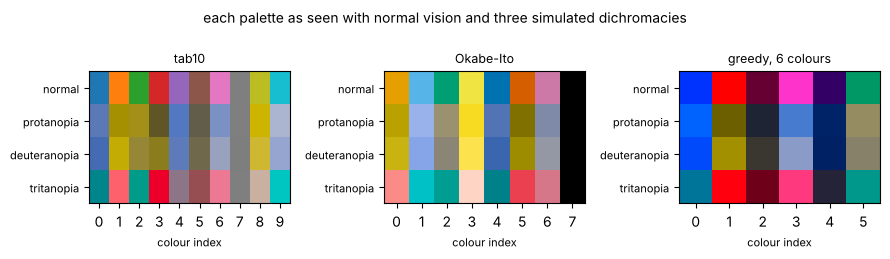

In [6]:
grid = np.array(list(itertools.product(np.linspace(0, 1, 6), repeat=3)))
cand = grid[contrast(grid, WHITE) >= 3.0]
labs = np.stack([linear_to_lab(simulate_linear(cand, kind)) for kind in KINDS])              # 4 x m x 3
worst = np.linalg.norm(labs[:, :, None] - labs[:, None], axis=-1).min(axis=0)              # m x m, worst over vision types
i, j = np.unravel_index(worst.argmax(), worst.shape)
chosen = [i, j]
while len(chosen) < 6:
    score = worst[:, chosen].min(axis=1)
    score[chosen] = -1
    chosen.append(int(score.argmax()))
GREEDY = [to_hex(cand[k]) for k in chosen]
print(f"{len(cand)} of {len(grid)} candidates pass 3:1 on white; greedy palette: {GREEDY}")

def worst_case(pal):
    D, _ = pairwise_de(pal)
    return D.min(axis=1)

print(f"{'palette (6 colours)':28s} worst Delta E: normal  protan  deutan  tritan | all | min contrast on white")
for name, pal in [("tab10 C0-C5", TAB10[:6]), ("Okabe-Ito without black, yellow", [h for h in OKABE_ITO if h not in ("#000000", "#F0E442")]),
                  ("greedy (this search)", GREEDY)]:
    w = worst_case(pal)
    print(f"{name:32s} " + "  ".join(f"{v:6.1f}" for v in w) + f" | {w.min():4.1f} | {min(contrast(hex_to_rgb(h), WHITE) for h in pal):.2f}:1")

fig, ax = plt.subplots(1, 3, figsize=(9, 2.6))
for a, (name, pal) in zip(ax, [("tab10", TAB10), ("Okabe-Ito", OKABE_ITO), ("greedy, 6 colours", GREEDY)]):
    P = np.array([hex_to_rgb(h) for h in pal])
    rows = np.stack([linear_to_srgb(simulate_linear(P, kind)) for kind in KINDS])         # 4 x n x 3
    a.imshow(rows, aspect="auto"); a.set_title(name, fontsize=9)
    a.set_yticks(range(4)); a.set_yticklabels(KINDS, fontsize=8); a.set_xticks(range(len(pal)))
    a.set_xlabel("colour index", fontsize=8)
plt.suptitle("each palette as seen with normal vision and three simulated dichromacies", fontsize=10)
plt.tight_layout(); plt.show()

### 7. Do not rely on colour alone
WCAG success criterion 1.4.1 (Use of Color, level A) says colour must not be the only visual means of conveying information. Below, a line chart of four made-up series is drawn twice into an image (off screen), once with colour only and once with markers, line styles and labels at the line ends, and both images are passed through the deuteranopia simulation.

first four default colours under deuteranopia: closest pair #2ca02c vs #d62728, Delta E 7.3 (normal vision: 119.8)


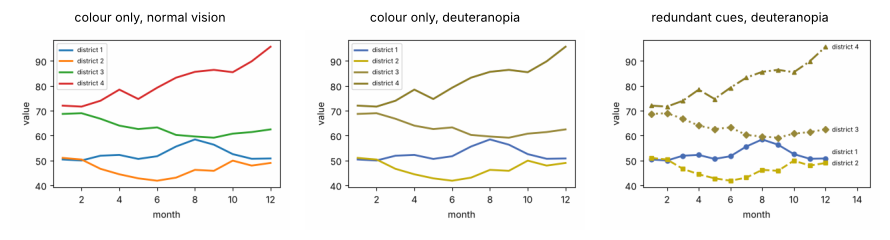

runtime so far 1.6 s


In [7]:
rng = np.random.default_rng(0)
months = np.arange(1, 13)
series = {f"district {k + 1}": 50 + 8 * k + np.cumsum(rng.normal(0, 3, 12)) for k in range(4)}

def label_heights(ends, gap=4.5):
    # move end-of-line labels apart so that no two are closer than `gap`
    order = np.argsort(ends); pos = np.array(ends, dtype=float)
    for a_, b_ in zip(order[:-1], order[1:]):
        pos[b_] = max(pos[b_], pos[a_] + gap)
    return pos

def render_chart(redundant):
    f = Figure(figsize=(4.2, 3.0), dpi=100); canvas = FigureCanvasAgg(f); a = f.add_subplot()
    ys = label_heights([y[-1] for y in series.values()])
    for k, (name, y) in enumerate(series.items()):
        style = dict(marker="osD^"[k], linestyle=["-", "--", ":", "-."][k], markersize=5) if redundant else {}
        a.plot(months, y, color=TAB10[k], lw=2, **style)
        if redundant:
            a.text(12.4, ys[k], name, fontsize=7, va="center", color="black")
    if not redundant:
        a.legend(list(series), fontsize=7, loc="upper left")
    a.set_xlim(0.5, 14.8 if redundant else 12.5); a.set_xlabel("month"); a.set_ylabel("value")
    f.tight_layout(); canvas.draw()
    return np.asarray(canvas.buffer_rgba())[..., :3] / 255.0

D4, prs4 = pairwise_de(TAB10[:4])
k = KINDS.index("deuteranopia")
i, j = prs4[D4[k].argmin()]
print(f"first four default colours under deuteranopia: closest pair {TAB10[i]} vs {TAB10[j]}, Delta E {D4[k].min():.1f} "
      f"(normal vision: {D4[0][D4[k].argmin()]:.1f})")
fig, ax = plt.subplots(1, 3, figsize=(9, 2.6))
views = [("colour only, normal vision", render_chart(False), "normal"), ("colour only, deuteranopia", render_chart(False), "deuteranopia"),
         ("redundant cues, deuteranopia", render_chart(True), "deuteranopia")]
for a, (title, im, kind) in zip(ax, views):
    a.imshow(linear_to_srgb(simulate_linear(im, kind))); a.set_title(title, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.1f} s")

### 8. Cross-check with a colour-science library (NOT RUN here)
The `colour-science` package implements the same Machado et al. matrices, interpolated for any severity between 0 and 1, and the newer CIEDE2000 colour difference. It is not installed here; on Colab or Kaggle run `pip install colour-science` first.

In [ ]:
# NOT RUN: needs the colour-science package (pip install colour-science), which is not installed here
import colour
M_lib = colour.matrix_cvd_Machado2009("Deuteranomaly", 1.0)
print("largest difference from our deuteranopia matrix:", np.abs(M_lib - CVD["deuteranopia"]).max())
M_half = colour.matrix_cvd_Machado2009("Deuteranomaly", 0.5)        # a milder, more common form (anomalous trichromacy)
P = np.array([hex_to_rgb(h) for h in TAB10])
lab = colour.XYZ_to_Lab(colour.sRGB_to_XYZ(colour.cctf_encoding(np.clip(srgb_to_linear(P) @ M_half.T, 0, 1))))
d2000 = colour.delta_E(lab[:, None], lab[None], method="CIE 2000")
print("smallest CIEDE2000 difference in tab10 at severity 0.5:", d2000[np.triu_indices(10, 1)].min())

### 9. Exercises

In [8]:
# TODO: nearest passing colour. Write nearest_passing(fg, bg, target) that tries BOTH darkening and lightening
# (use shade_to_pass), keeps the versions that reach the target contrast, and returns the one with the smaller
# CIELAB Delta E from the original colour. Test it on the matplotlib orange #ff7f0e as text on white and on #555555.
def nearest_passing(fg_hex, bg_hex, target=4.5):
    return None          # replace with your code: return the passing colour as a hex string

r = nearest_passing("#ff7f0e", "#555555")
print("not done yet" if r is None else f"nearest passing colour: {r}")

not done yet


In [9]:
# TODO: milder colour vision deficiency. Most people with colour vision deficiency are anomalous trichromats, not
# dichromats. Below are Machado et al.'s severity-0.5 matrices. Add them to the analysis of section 5 and report the
# smallest pairwise Delta E of tab10 at severity 0.5 and 1.0 for protan and deutan deficiency.
CVD_HALF = {"protanomaly 0.5": np.array([[0.458064, 0.679578, -0.137642], [0.092785, 0.846313, 0.060902], [-0.007494, -0.016807, 1.024301]]),
            "deuteranomaly 0.5": np.array([[0.547494, 0.607765, -0.155259], [0.181692, 0.781742, 0.036566], [-0.010410, 0.027275, 0.983136]])}
def smallest_de_half(pal):
    return None          # replace with your code: a dict {name: smallest pairwise Delta E}

r = smallest_de_half(TAB10)
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **The threshold is sharp.** Black on white gives 21.00:1. Grey `#777777` has luminance 0.1845 and a contrast of 4.478:1 on white, so it fails AA for normal text by a very small margin, while `#767676`, one step darker, gives 4.542:1 and passes. Checkers compare the unrounded ratio with 4.5.
2. **Common colours fail.** Light grey placeholder text (`#999999`, 2.85:1), white text on matplotlib's orange (2.53:1), the Okabe–Ito orange (2.25:1) and dark grey text on a near-black dark-mode background (2.51:1) fail every threshold. Pure red error text (4.00:1) passes only the 3:1 level for large text and graphics.
3. **Small changes fix most failures.** Darkening matplotlib's orange by 8.4% (to `#ea740d`) reaches 3:1 for chart lines; text needs 26.9% (`#bb5d0a`). On the `#121212` dark background, the purple `#9467bd` needed only a 1.3% lightening to reach 4.5:1.
4. **Dichromacy removes one colour axis.** In the flower photo, the spread of the green–red channel $a^*$ fell from 19.42 to 1.89 (protanopia) and 2.56 (deuteranopia): the orange flower turns yellow and the green leaves turn grey. In the tritanopia simulation the blue–yellow channel $b^*$ fell from 20.73 to 11.21, while $a^*$ rose to 26.26, because the simulated flower turns pink. Treat the tritan result as rougher than the other two.
5. **Default chart colours collide.** With normal vision the closest pair in matplotlib's `tab10` palette is 27.7 apart ($\Delta E$). Under protanopia the orange and green lines are only 4.6 apart, and under deuteranopia orange and olive are 7.2 apart, with 4 pairs below 10. In the four-line chart, green and red were 119.8 apart for normal vision and 7.3 under deuteranopia.
6. **"Colour-blind safe" is not "high contrast".** The Okabe–Ito palette kept every pair at least 16.1 apart in all four vision types, but three of its eight colours fail 3:1 on white (orange 2.25:1, sky blue 2.31:1, yellow 1.32:1), as do four of the ten `tab10` colours. Darken them before using them for thin chart lines on a white page.
7. **A search can satisfy both, with caveats.** Of 216 grid colours, 118 pass 3:1 on white. The greedy max–min palette (`#0033ff`, `#ff0000`, `#660033`, `#ff33cc`, `#330066`, `#009966`) kept every pair at least 30.0 apart in all four vision types, against 4.6 for `tab10` C0–C5 and 16.1 for six Okabe–Ito colours. But it was chosen to maximize exactly this score, CIE76 $\Delta E$ only roughly follows perception, and pure red next to hot pink is not pleasant to read. Check any palette with real users, and add markers, line styles and direct labels as in section 7, so that colour is never the only cue.